# Football Managerial Decision Analytics — Chapter 03
## Pitch, spatial and tactical analysis

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate (or fetch) the project code, import the shared package, load the workspace
import os, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/blazingarrows1525/football-managerial-decision-analytics"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists()), None)
if ROOT is None:  # opened on its own (e.g. Google Colab): fetch the project code once, next to this notebook
    ROOT = Path.cwd() / "football-managerial-decision-analytics"
    if not (ROOT / "src" / "workspace.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("FMA_PROJECT_ROOT", str(ROOT))  # data cache and outputs live inside the project folder

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.8s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## E · Pitch, spatial and tactical analysis

**Research question.** Where does the team play, how does it move the ball forward, and through whom?

**Data and method.** StatsBomb coordinates: a 120 × 80 pitch with the origin at the top-left corner, and
**every team recorded attacking left to right in both halves**. No per-half flip is applied. Maps that draw
more than 4,000 points or 500 arrows show a seeded random sample and say so.

In [2]:
from src.features.event_features import EVENT_KINDS, select_events
from src.visualization import spatial

fl = ws.flags
tid = ws.team_id()
# Orientation check on the data: shots must cluster near x = 120 for both teams and in both halves
sh = fl[fl.type == "Shot"]
display(sh.assign(side=np.where(sh.team_id == tid, FOCUS, "opponents")).groupby(["side", "period"]).x.agg(["size", "median", "min"]).round(1))
m2 = spatial.mirror(sh.head(3)[["x", "y"]])
print("mirror() flips both axes:", sh.head(3)[["x", "y"]].round(1).values.tolist(), "→", m2.round(1).values.tolist())
interpret(f"Median shot location is x = {sh.x.median():.0f} for every team and half, confirming that the source records "
          f"each team attacking towards x = 120 throughout. The coordinate transform is covered by `tests/test_chart_renderers.py`.")

size  median    min
side             period                     
Bayer Leverkusen 1        294 105.000 86.600
                 2        329 105.900 57.700
opponents        1        145 105.900 73.700
                 2        148 104.700 79.400

mirror() flips both axes: [[92.2, 27.1], [107.0, 23.2], [96.2, 44.8]] → [[27.8, 52.9], [13.0, 56.8], [23.8, 35.2]]


**Interpretation.** Median shot location is x = 105 for every team and half, confirming that the source records each team attacking towards x = 120 throughout. The coordinate transform is covered by `tests/test_chart_renderers.py`.

03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund


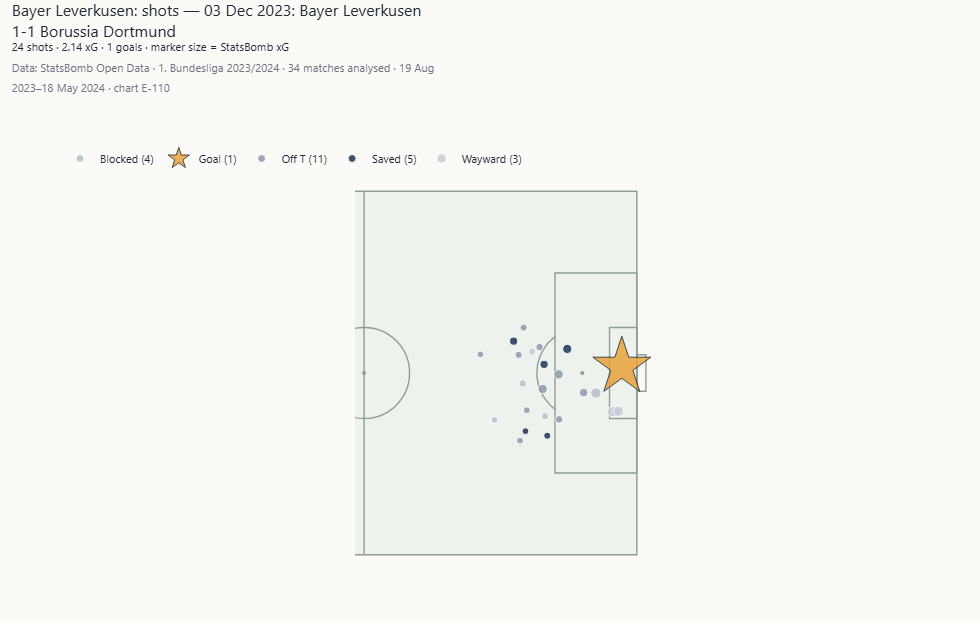

`E-110` Team shot map · *Method:* Marker size = StatsBomb xG; star = goal.

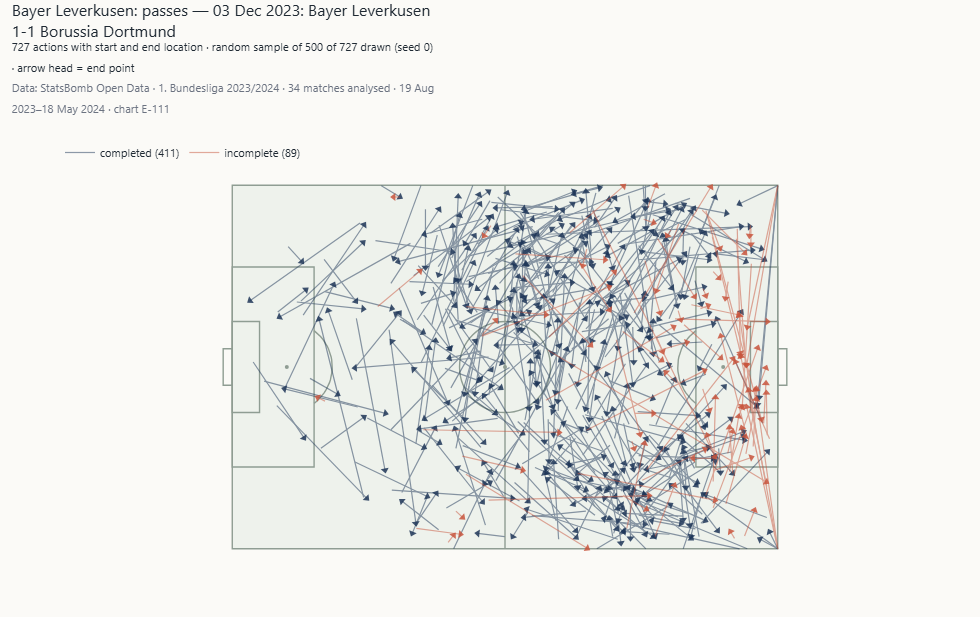

`E-111` Pass map with arrows · *Method:* Arrow heads at the end point; failed passes in red. · *Caveat:* Random sample of 500 arrows when larger.

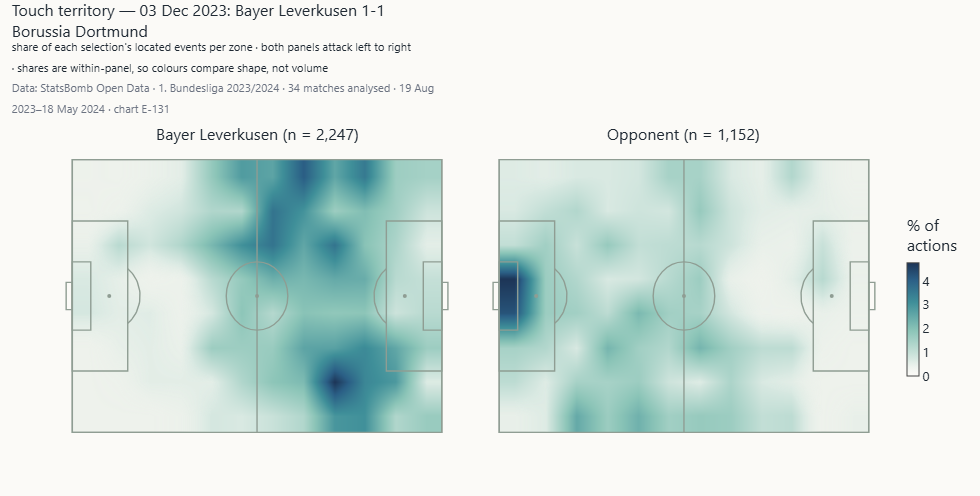

`E-131` Spatial comparison team versus opponent · *Method:* Zone shares side by side. · *Caveat:* Shares are within-panel.

In [3]:
mid = ws.default_match()
print(ws.match_label(mid))
show("E-110", ws, match_id=mid)
show("E-111", ws, match_id=mid)
show("E-131", ws, match_id=mid)

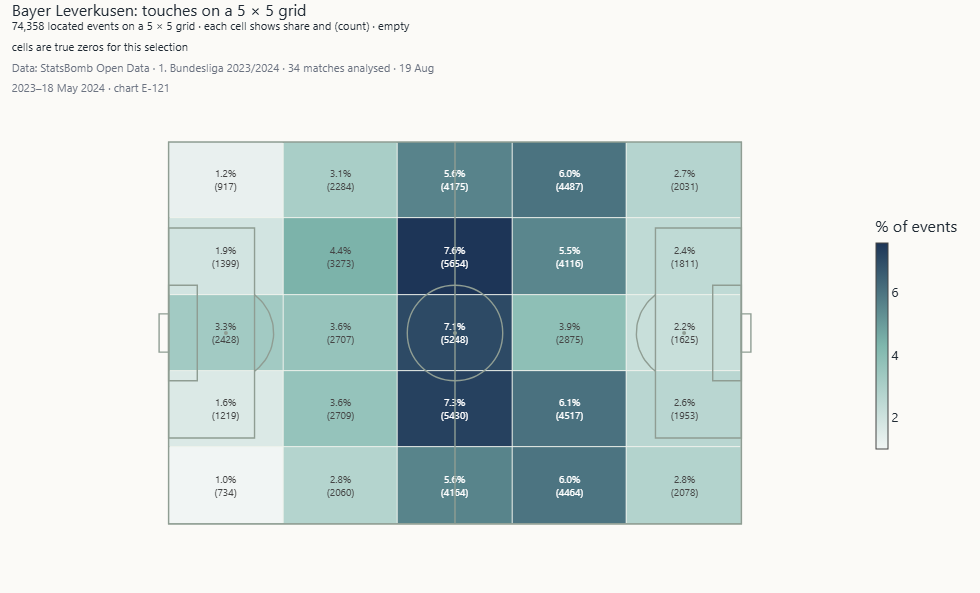

`E-121` Zone heatmaps (3×3, 5×5, tactical) · *Method:* Counts and shares per cell.

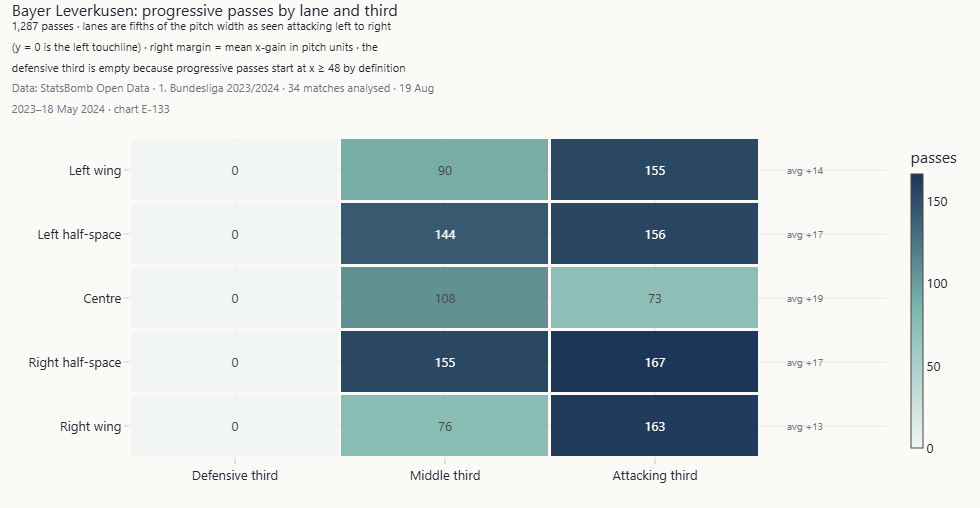

`E-133` Pass progression lanes · *Method:* Five lanes × three thirds by pass origin.

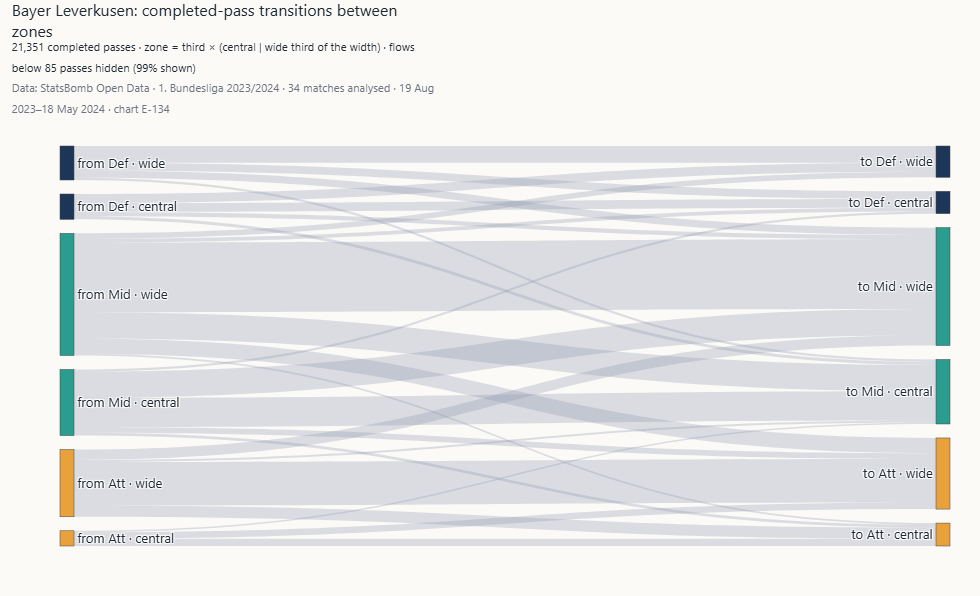

`E-134` Event transition Sankey · *Method:* Zone = third × (central | wide). · *Caveat:* Small flows hidden; share shown stated.

**Interpretation.** 30% of the team's 74,358 touches are in the attacking third and 19% in its own third. Of 1,287 progressive passes, 25% start in the right half-space and 14% in the centre.

**Managerial implication.** The lanes used for progression show where an opponent's block is most often played through — and where the team's own access would suffer if that side were closed.

**Limitation.** Event locations are where the ball was; off-ball positioning is not in event data.

In [4]:
from src.analytics import descriptive as desc
touches = select_events(fl, "Touches", team_id=tid)
zt = desc.zone_table(touches, 3, 1)
show("E-121", ws, kind="Touches")
show("E-133", ws)
show("E-134", ws)
share = (zt.iloc[0] / zt.values.sum())
prog = select_events(fl, "Progressive passes", team_id=tid)
lane = pd.Series(np.clip((prog.y / 80 * 5).astype(int), 0, 4)).map(dict(enumerate(spatial.LANES))).value_counts(normalize=True)
interpret(f"{share.iloc[2]:.0%} of the team's {len(touches):,} touches are in the attacking third and {share.iloc[0]:.0%} in "
          f"its own third. Of {len(prog):,} progressive passes, {lane.iloc[0]:.0%} start in the {lane.index[0].lower()} "
          f"and {lane.iloc[-1]:.0%} in the {lane.index[-1].lower()}.")
implication("The lanes used for progression show where an opponent's block is most often played through — and "
            "where the team's own access would suffer if that side were closed.")
limitation("Event locations are where the ball was; off-ball positioning is not in event data.")

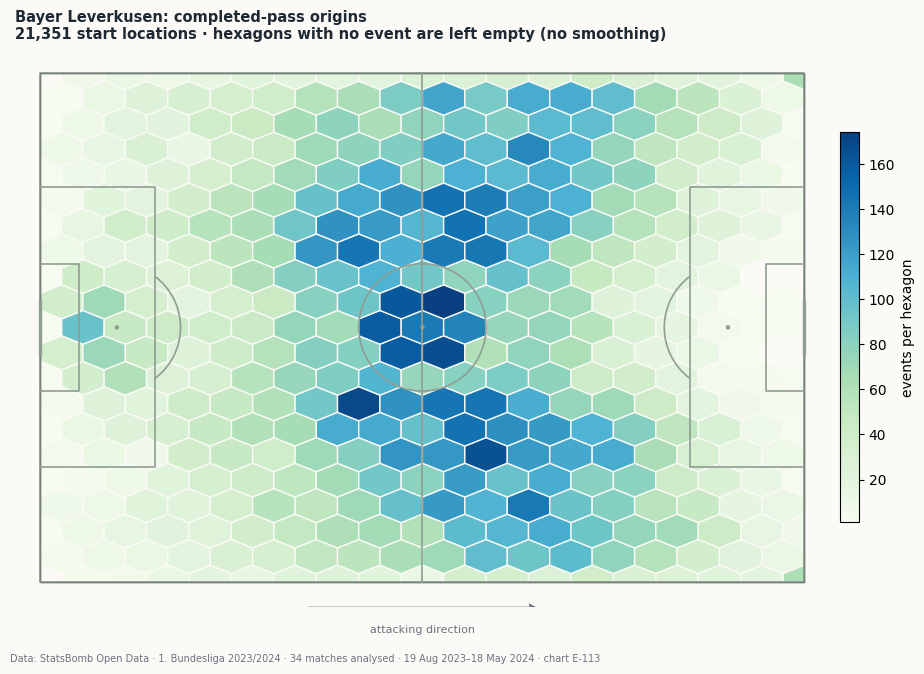

`E-113` Pass-origin hexbin · *Method:* Hexagonal counts of start locations.

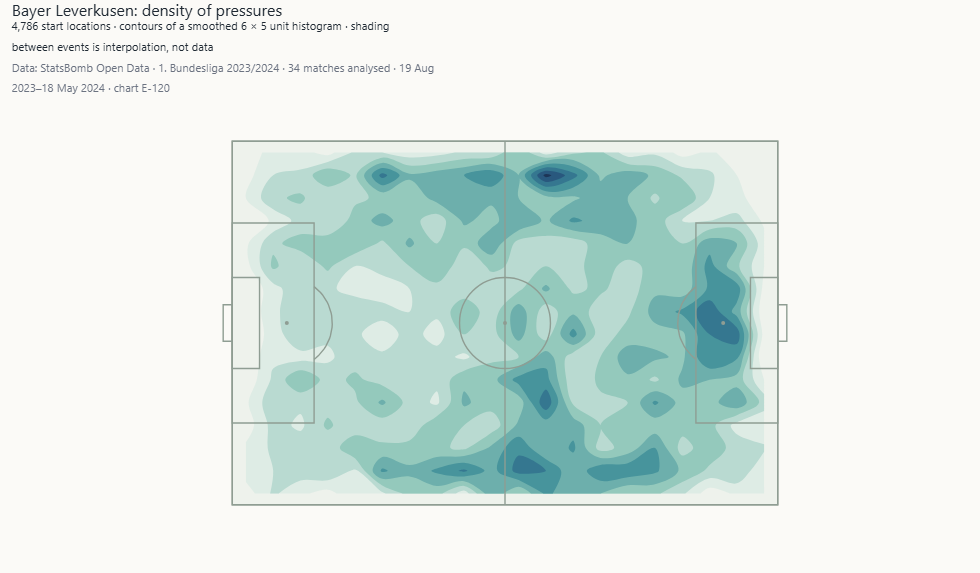

`E-120` KDE event distribution · *Method:* Smoothed contours. · *Caveat:* Shading between events is interpolation.

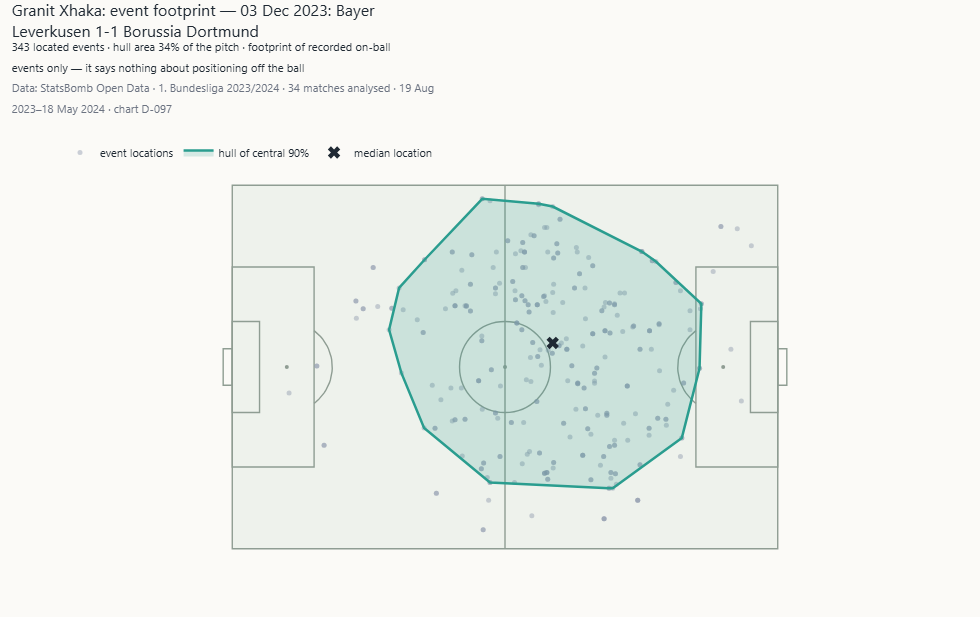

`D-097` Convex hull of touch locations · *Method:* Hull of the central 90% of touch locations in one match. · *Caveat:* An event footprint, not the area the player occupied.

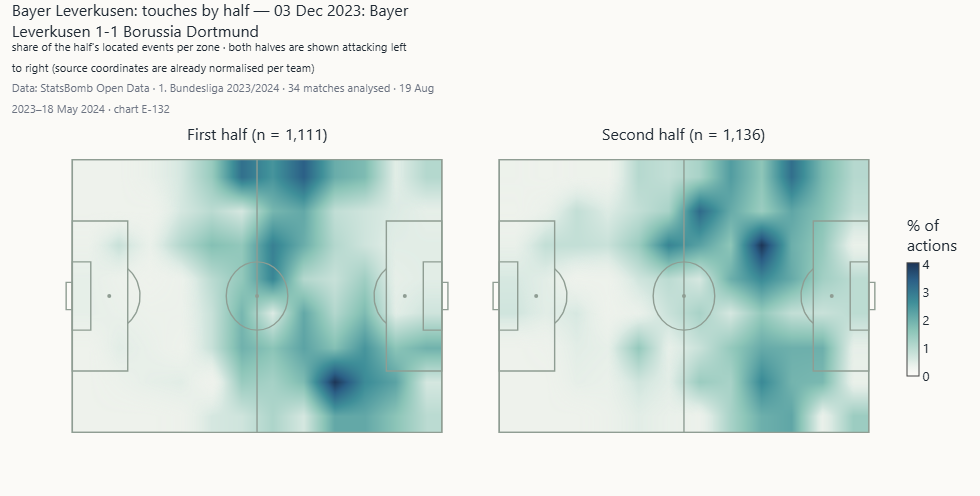

`E-132` Half-by-half location maps · *Method:* Both halves shown attacking left to right.

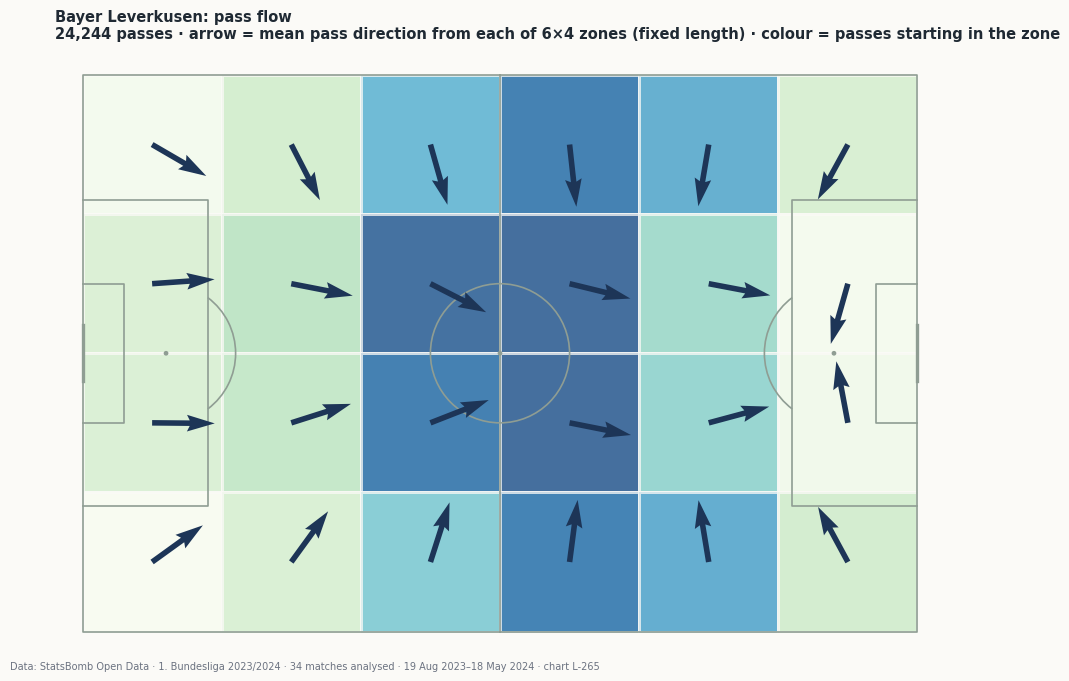

`L-265` Pass-flow map · *Method:* Mean pass direction per zone.

In [5]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("E-113", ws)
    show("E-120", ws, kind="Pressures")
    show("D-097", ws, player_id=ws.default_player(), match_id=mid)
    show("E-132", ws, match_id=mid)
    show("L-265", ws)

### Expected Threat (project-computed)

**Question.** Which areas carry the most threat in these matches, and who moves the ball into them?

**Method.** A 16 × 12 grid; moves are passes and carries; a failed pass passes on no value; the value of a shot
from a cell is the mean StatsBomb xG of shots taken there; the surface is the fixed point of
`xT(c) = P(shot|c)·value(c) + P(move|c)·Σ T(c→c')·xT(c')`. It is **fitted on the analysed matches themselves**
and is a derived project value, not a StatsBomb field.

,check,passed,detail
0,Value iteration converged,True,79 iterations
1,"All values within [0, 1]",True,"min 0.0029, max 0.2927"
2,Final third more valuable than own third,True,0.0490 vs 0.0075
3,Highest-value cell lies in the attacking penal...,True,"cell row 6, col 15 of 12 x 16"


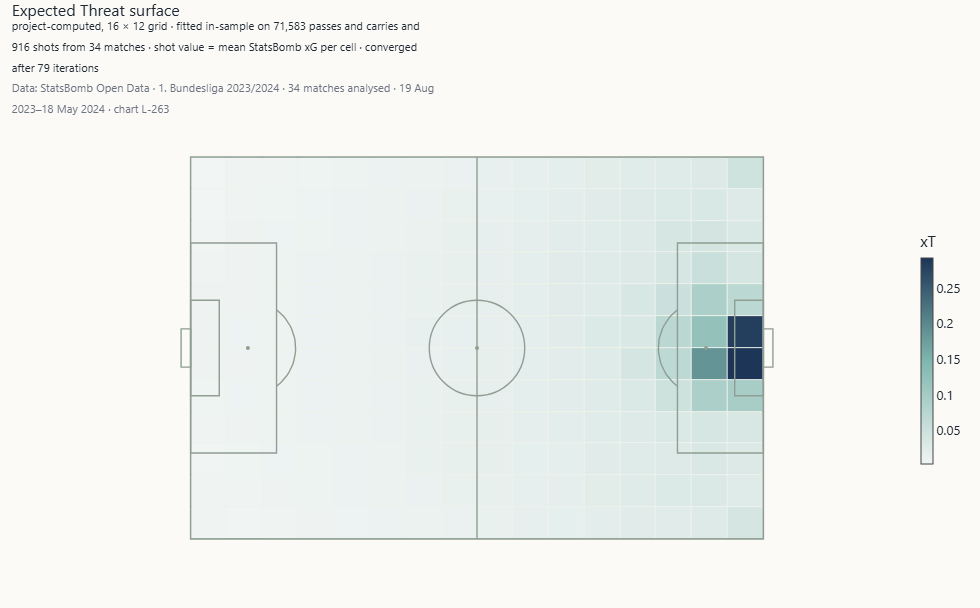

`L-263` Expected Threat surface · *Method:* Project-computed xT, 16 × 12 grid, value iteration. · *Caveat:* Fitted in-sample on the analysed matches; not a StatsBomb field.

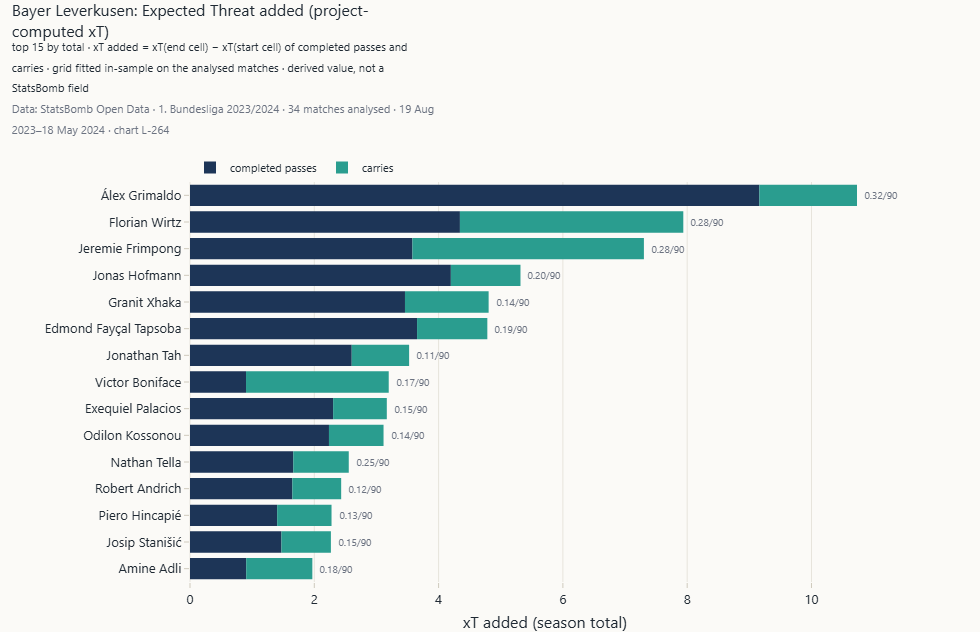

`L-264` xT added by player · *Method:* xT(end) − xT(start) of completed passes and carries. · *Caveat:* Derived project value on an in-sample grid.

**Interpretation.** The grid was fitted on 71,583 passes and carries and 916 shots and converged in 79 iterations; the highest cell is worth 0.293. Álex Grimaldo added the most threat (10.7; 9.2 by passing, 1.6 by carrying).

**Limitation.** In-sample and descriptive: with 34 matches the surface is noisy cell by cell, and it credits only the player who moved the ball.

In [6]:
from src.features import values
g = ws.xt_grid()
display(values.xt_sanity(g))
show("L-263", ws)
show("L-264", ws)
px = ws.player_xt(); mine = px[px.team_name == FOCUS].head(3)
interpret(f"The grid was fitted on {g.n_moves:,} passes and carries and {g.n_shots:,} shots and converged in {g.iterations} "
          f"iterations; the highest cell is worth {g.grid.max():.3f}. {mine.player_name.iloc[0]} added the most threat "
          f"({mine.xt_total.iloc[0]:.1f}; {mine.xt_pass.iloc[0]:.1f} by passing, {mine.xt_carry.iloc[0]:.1f} by carrying).")
limitation("In-sample and descriptive: with 34 matches the surface is noisy cell by cell, and it credits only the "
           "player who moved the ball.")

## F · Passing networks

**Question.** Who connects the team, and how dependent is the structure on individual players?

**Method.** One directed graph per match from completed passes before the first substitution, so every node
shared the pitch. Node position = mean pass origin; PageRank is weighted by pass count; betweenness uses
1 / passes as distance.

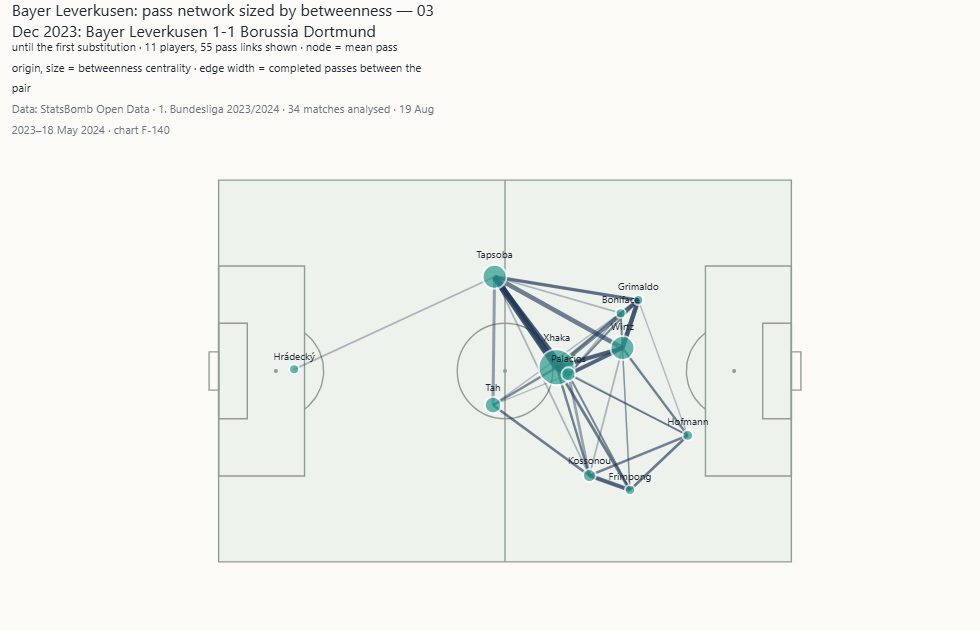

`F-140` Network with centrality-sized nodes · *Method:* Node size and edge width defined in the subtitle.

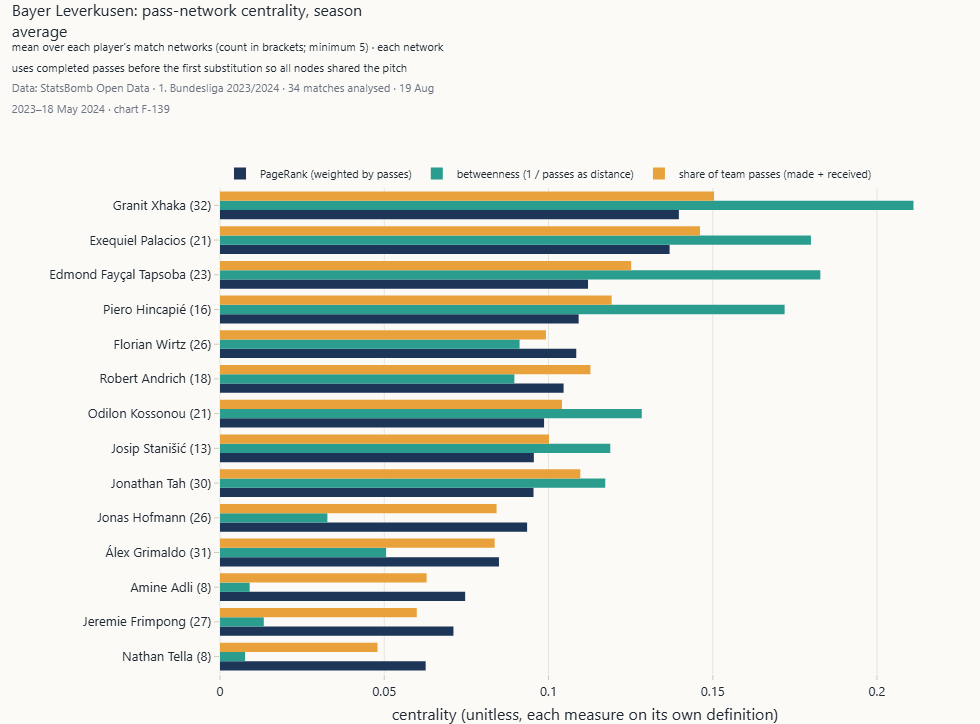

`F-139` Network node centrality · *Method:* PageRank, betweenness and pass share averaged over match networks.

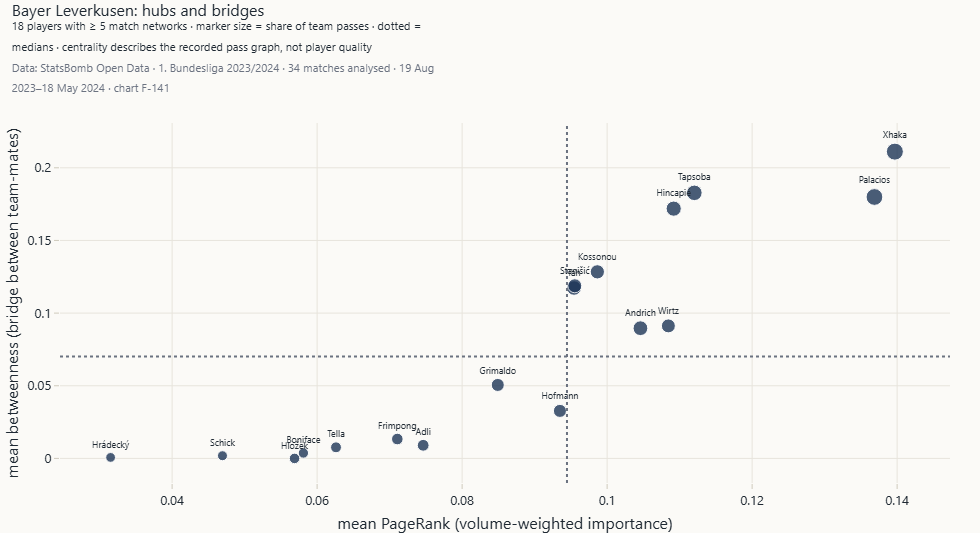

`F-141` Network centrality comparison · *Method:* PageRank vs betweenness, size = pass share.

**Interpretation.** Across 34 match networks Granit Xhaka has both the highest mean PageRank (0.140) and the highest mean betweenness (0.211). The four highest-PageRank players are Granit Xhaka, Exequiel Palacios, Edmond Fayçal Tapsoba, Piero Hincapié.

**Managerial implication.** A structure that runs through one or two players is efficient and exposed: plan the build-up for matches in which the hub is pressed or absent.

**Limitation.** Centrality describes the recorded pass graph; it is not a measure of player quality.

In [7]:
show("F-140", ws, match_id=mid)
show("F-139", ws)
show("F-141", ws)
cs = ws.centrality_summary()
hub, bridge = cs.iloc[-1], cs.sort_values("betweenness").iloc[-1]
who = (f"{hub.player} has both the highest mean PageRank ({hub.pagerank:.3f}) and the highest mean betweenness "
       f"({bridge.betweenness:.3f})" if hub.player == bridge.player else
       f"{hub.player} has the highest mean PageRank ({hub.pagerank:.3f}) and {bridge.player} the highest mean "
       f"betweenness ({bridge.betweenness:.3f})")
interpret(f"Across {ws.centrality().match_id.nunique()} match networks {who}. "
          f"The four highest-PageRank players are {', '.join(cs.player.tail(4)[::-1])}.")
implication("A structure that runs through one or two players is efficient and exposed: plan the build-up for "
            "matches in which the hub is pressed or absent.")
limitation("Centrality describes the recorded pass graph; it is not a measure of player quality.")

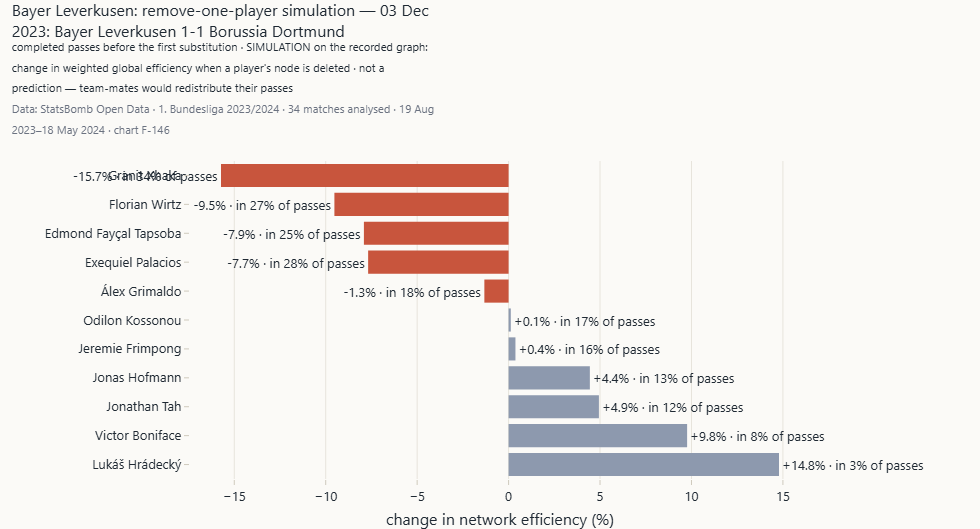

`F-146` Network robustness (remove-node simulation) · *Method:* Change in weighted global efficiency when a node is deleted. · *Caveat:* A simulation on the recorded graph, not a match forecast.

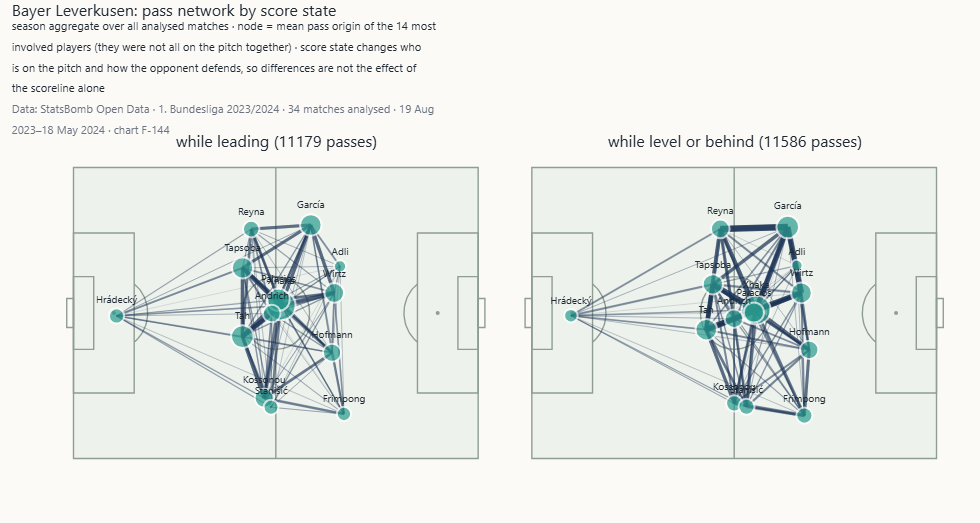

`F-144` Network change by score state · *Method:* Season passes split by the team's score state. · *Caveat:* Score state is confounded with personnel and opponent behaviour.

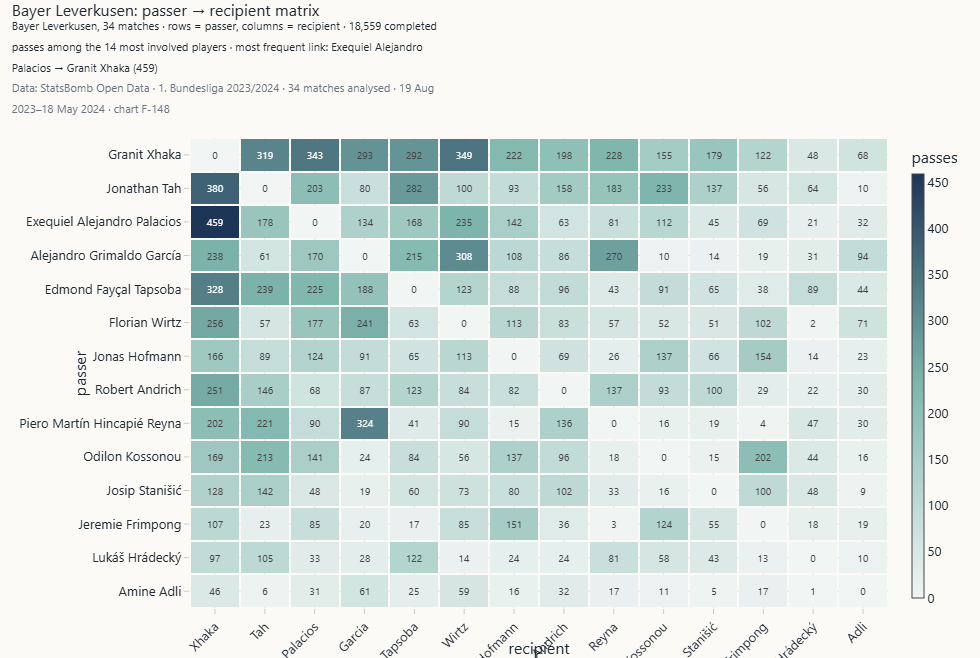

`F-148` Player pair passing heatmap · *Method:* Completed passes among the 14 most involved players.

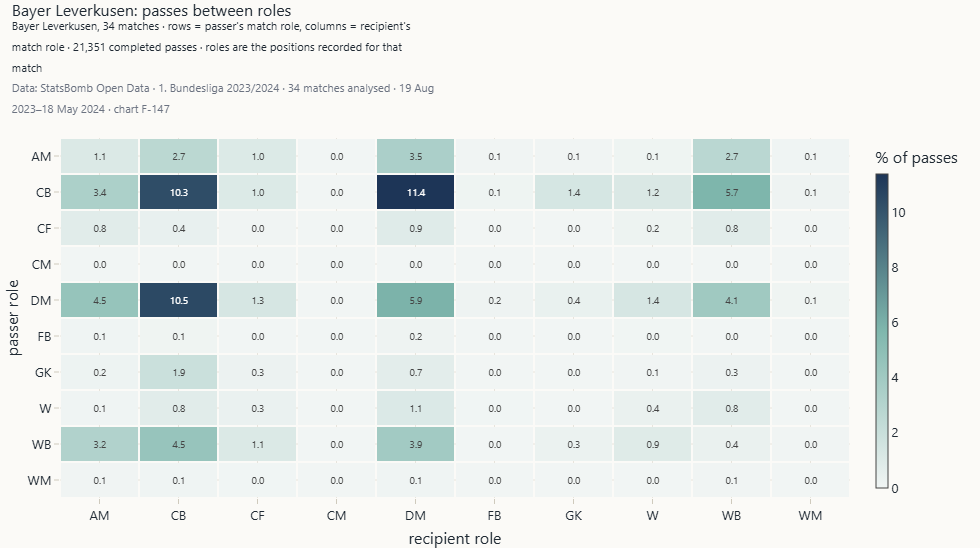

`F-147` Role interaction matrix · *Method:* Passer role × recipient role.

In [8]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("F-146", ws, match_id=mid)
    show("F-144", ws)
    show("F-148", ws)
    show("F-147", ws)

### Formations and what cannot be drawn

A formation here is the label recorded on the Starting XI or Tactical Shift event — a nominal description, not
the team's shape in and out of possession.

,starting_formation,matches,wins,draws,losses,points_per_match,xg_for,xg_against,goals_for,goals_against,possession_proxy_pct,field_tilt_pct,sample_warning
0,3-4-2-1,25,23,2,0,2.840,2.050,0.740,2.680,0.640,62.780,68.290,
1,3-4-3,8,4,4,0,2.000,2.440,1.100,2.500,0.880,58.400,66.920,
2,3-4-1-2,1,1,0,0,3.000,1.820,0.460,2.000,1.000,61.070,56.020,n<3: descriptive only


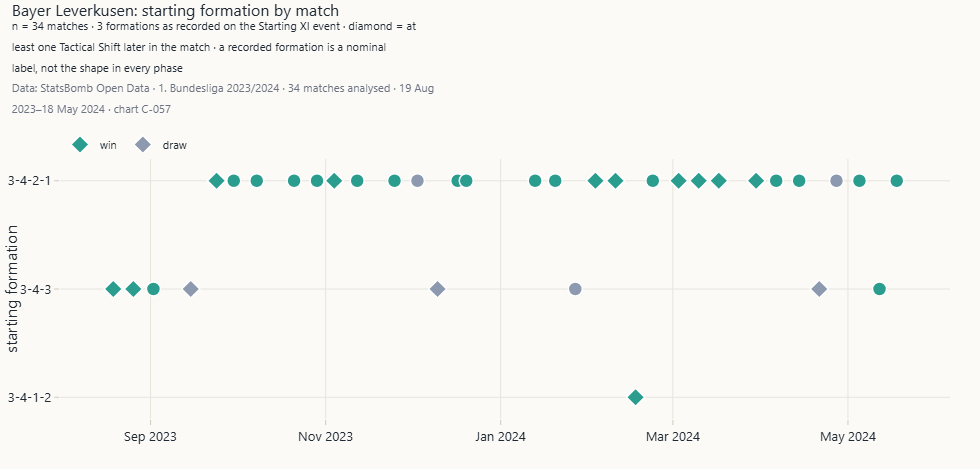

`C-057` Formation usage timeline · *Method:* Recorded Starting XI formation by date. · *Caveat:* A nominal label, not the shape in every phase.

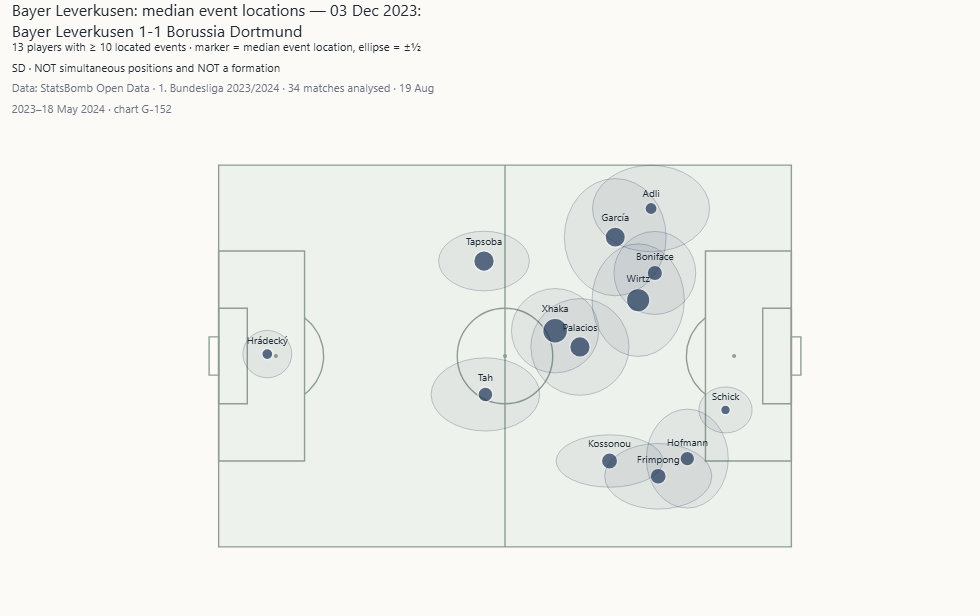

`G-152` Team shape from event locations · *Method:* Median touch location per player. · *Caveat:* Not simultaneous positions and not a formation.

**Interpretation.** Bayer Leverkusen started in 3 formations; 3-4-2-1 in 25 of 34 matches. Differences in results between formations are confounded by opponent and availability.

E-126 Voronoi diagram: not implemented — Needs every player's position at the same instant. Event data give one actor per event, and 360 freeze frames show only players inside the camera view, so a Voronoi partition would be invented space.
E-127 Delaunay triangulation: not implemented — Needs simultaneous positions of all team-mates (tracking data); not derivable from event locations.
E-128 Pitch-control / space-control map: not implemented — Needs positions and velocities of all 22 players (tracking). Never approximated from event x/y.


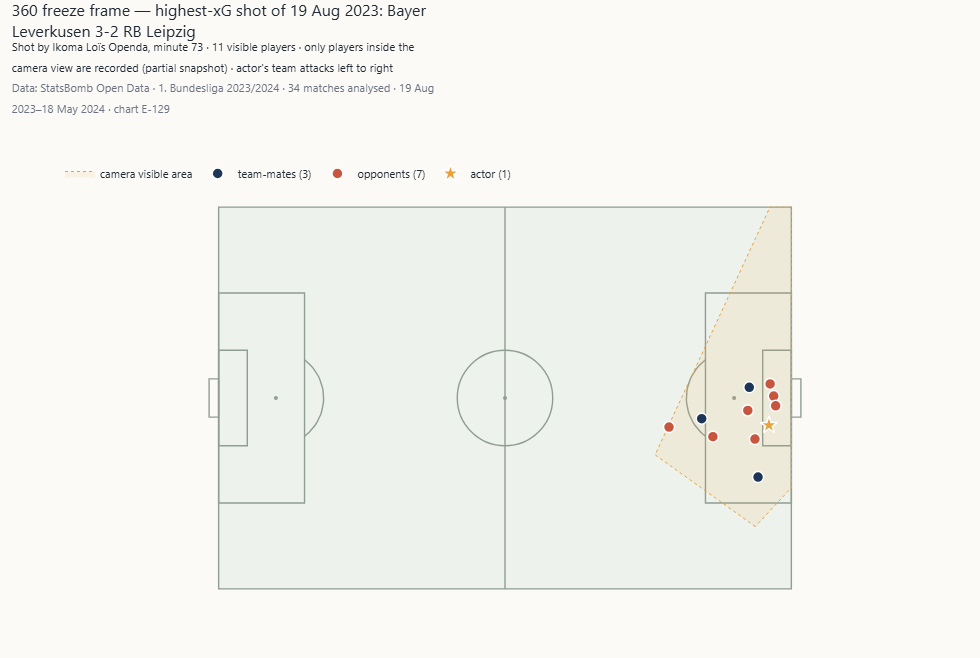

`E-129` 360 freeze-frame plot · *Method:* StatsBomb 360 frame of the match's highest-xG shot. · *Caveat:* Only players in the camera view are recorded.

In [9]:
from src.features.team_features import formation_summary
from src.visualization import registry
fs = formation_summary(B.team_stats, FOCUS)
display(fs)
show("C-057", ws)
show("G-152", ws, match_id=mid)
interpret(f"{FOCUS} started in {len(fs)} formations; {fs.starting_formation.iloc[0]} in {int(fs.matches.iloc[0])} of {len(tm)} "
          f"matches. Differences in results between formations are confounded by opponent and availability.")
for cid in ("E-126", "E-127", "E-128"):
    s = registry.get(cid)
    print(f"{cid} {s.name}: not implemented — {s.unavailable_reason}")
show("E-129", ws, match_id=int(tm.match_id.iloc[0]))